# 02 - Evaluasi model (STEM-Err-ID)
**Aturan:** satu model per sesi. Setelah satu model selesai, *Runtime > Restart session*, ubah `NAMA_MODEL` di sel Konfigurasi, lalu jalankan lagi dari atas.
Runtime harus GPU (T4). Prasyarat: `sains_bersih.csv` sudah dibuat notebook 01.
Model yang sudah selesai akan langsung berhenti dengan pesan "Sudah selesai", jadi tidak ada hasil dobel.

In [7]:
!pip -q install -U transformers accelerate tqdm statsmodels

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.4/57.4 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 98.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.2/80.2 kB 8.1 MB/s eta 0:00:00


In [8]:
# 1. Konfigurasi (HANYA sel ini yang biasanya diubah)
NAMA_MODEL = "TinyLlama/TinyLlama-1.1B-Chat-v1.0"   # cek nama persis di Hugging Face
N_SHOT = 0                        # 0 = zero-shot, 3 = few-shot
PILOT = 100                      # angka 100 untuk uji cepat, None = semua soal
OUT_DIR = "/content/drive/MyDrive/stem_err_id"

In [9]:
# 2. Persiapan + baca data bersih
import os, json, gc, math, glob
import torch, pandas as pd
from tqdm.auto import tqdm
from google.colab import drive
drive.mount("/content/drive")

try:
    from google.colab import userdata
    HF_TOKEN = userdata.get("HF_TOKEN")   # opsional: simpan token di Colab Secrets
except Exception:
    HF_TOKEN = None

assert torch.cuda.is_available(), "GPU tidak aktif. Runtime > Change runtime type > T4 GPU"
print("GPU:", torch.cuda.get_device_name(0))

sains = pd.read_csv(f"{OUT_DIR}/sains_bersih.csv", index_col="id")
sains["opsi_list"] = sains["opsi_list"].apply(json.loads)
print(len(sains), "soal |", sains["mapel"].value_counts().to_dict())
print("CATAT jumlah soal ini; harus sama di semua anggota:", len(sains))

HURUF = list("ABCDE")

def soal_teks(r):
    opsi = "\n".join(f"{h}. {o}" for h, o in zip(HURUF, r["opsi_list"]))
    return f"{r['soal']}\n{opsi}\nJawaban:"

def buat_prompt(r, n_shot):
    kepala = (f"Ini adalah soal {r['mapel']} untuk {r['jenjang']}. "
              "Pilihlah salah satu jawaban yang dianggap benar!\n\n")
    contoh = ""
    if n_shot > 0:
        pool = sains[sains["mapel"] == r["mapel"]].drop(index=r.name)
        shots = pool.sample(n_shot, random_state=42)
        contoh = "".join(soal_teks(s) + f" {s['kunci']}\n\n" for _, s in shots.iterrows())
    return kepala + contoh + soal_teks(r)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: Tesla T4
2925 soal | {'IPA': 950, 'Biologi': 845, 'Kimia': 683, 'Fisika': 447}
CATAT jumlah soal ini; harus sama di semua anggota: 2925


In [10]:
# 3. Fungsi evaluasi (checkpoint otomatis, lanjut kalau sesi putus)
def jalankan(nama_model, n_shot=0, pilot=None, hf_token=None):
    from transformers import AutoTokenizer, AutoModelForCausalLM
    nama = nama_model.split("/")[-1]
    path = f"{OUT_DIR}/hasil_{nama}_{n_shot}shot{'_pilot' if pilot else ''}.csv"
    target = sains.sample(pilot, random_state=42) if pilot else sains
    rows = pd.read_csv(path).to_dict("records") if os.path.exists(path) else []
    selesai = {int(r["id"]) for r in rows}
    if len(selesai) >= len(target):
        print("Sudah selesai:", path)
        return path
    print(f"{nama} | {n_shot}-shot | selesai {len(selesai)}/{len(target)}")

    tok = AutoTokenizer.from_pretrained(nama_model, token=hf_token)
    tok.truncation_side = "left"   # potong awal prompt supaya "Jawaban:" tetap ada
    model = AutoModelForCausalLM.from_pretrained(
        nama_model, torch_dtype=torch.float16, device_map="auto", token=hf_token).eval()
    ids = [(tok.encode(" " + h, add_special_tokens=False)[-1],
            tok.encode(h, add_special_tokens=False)[-1]) for h in HURUF]
    print("Token huruf:", ids)
    print("Memori GPU (GB):", round(torch.cuda.memory_allocated() / 1e9, 1))

    @torch.no_grad()
    def peluang(prompt, n):
        x = tok(prompt, return_tensors="pt", truncation=True, max_length=3000).to(model.device)
        lp = torch.log_softmax(model(**x).logits[0, -1].float(), dim=-1)
        sk = torch.stack([torch.logsumexp(torch.stack([lp[a], lp[b]]), 0) for a, b in ids[:n]])
        return torch.softmax(sk, dim=0).cpu().tolist()

    n_nan = 0
    for i, r in tqdm(target.iterrows(), total=len(target)):
        if int(i) in selesai:
            continue
        p = peluang(buat_prompt(r, n_shot), r["n_opsi"])
        if any(math.isnan(v) for v in p):
            n_nan += 1
            p = [1.0 / len(p)] * len(p)   # ditandai lewat hitungan NaN di bawah
        pred = HURUF[max(range(len(p)), key=lambda j: p[j])]
        row = dict(id=int(i), mapel=r["mapel"], jenjang=r["jenjang"], n_opsi=r["n_opsi"],
                   pred=pred, kunci=r["kunci"], benar=int(pred == r["kunci"]), p_pred=max(p))
        row.update({"p" + h: v for h, v in zip(HURUF, p)})
        rows.append(row)
        if len(rows) % 100 == 0:
            pd.DataFrame(rows).to_csv(path, index=False)

    hasil = pd.DataFrame(rows)
    hasil.to_csv(path, index=False)
    print("\nSelesai:", path)
    print("Akurasi:", round(hasil["benar"].mean(), 4), "| n =", len(hasil))
    print("Distribusi jawaban model:", hasil["pred"].value_counts(normalize=True).round(2).to_dict())
    if n_nan:
        print(f"PERINGATAN: {n_nan} soal menghasilkan NaN (fp16). Hasil model ini JANGAN dipakai sebelum dicek.")
    del model, tok
    gc.collect(); torch.cuda.empty_cache()
    return path

In [24]:
# 4. Jalankan model (sesuai Konfigurasi). Saran: PILOT=100 dulu untuk cek waktu)
path_hasil = jalankan(NAMA_MODEL, n_shot=N_SHOT, pilot=PILOT, hf_token=HF_TOKEN)

TinyLlama-1.1B-Chat-v1.0 | 0-shot | selesai 0/100


config.json:   0%|          | 0.00/608 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.29k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.84M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/551 [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

Token huruf: [(319, 319), (350, 350), (315, 315), (360, 360), (382, 382)]
Memori GPU (GB): 2.2


  0%|          | 0/100 [00:00<?, ?it/s]


Selesai: /content/drive/MyDrive/stem_err_id/hasil_TinyLlama-1.1B-Chat-v1.0_0shot_pilot.csv
Akurasi: 0.22 | n = 100
Distribusi jawaban model: {'D': 0.44, 'B': 0.28, 'C': 0.25, 'A': 0.03}


Model berikutnya: **Runtime > Restart session**, ganti `NAMA_MODEL` di sel Konfigurasi, jalankan ulang dari atas (sel install boleh dilewati kalau tidak restart ulang paket).

In [12]:
# 5. Rekap semua model. Bisa dijalankan kapan saja.
import glob, os
import pandas as pd
from statsmodels.stats.proportion import proportion_confint

# Mencari hasil penuh (*shot.csv) di OUT_DIR
files = sorted(glob.glob(f"{OUT_DIR}/hasil_*shot.csv"))

# Jika tidak ada hasil penuh, cari hasil pilot (*_pilot.csv) di OUT_DIR maupun di subfolder arsip_pilot
if not files:
    files = sorted(glob.glob(f"{OUT_DIR}/hasil_*shot_pilot.csv")) + \
            sorted(glob.glob(f"{OUT_DIR}/arsip_pilot/hasil_*shot_pilot.csv"))

assert files, f"Belum ada hasil evaluasi (baik penuh maupun pilot) ditemukan di {OUT_DIR} atau {OUT_DIR}/arsip_pilot."
baris, semua = [], {}
for f in files:
    h = pd.read_csv(f)
    lo, hi = proportion_confint(h["benar"].sum(), len(h), method="wilson")
    baris.append(dict(file=os.path.basename(f), n=len(h), akurasi=h["benar"].mean(),
                      ci_bawah=lo, ci_atas=hi, p_maks_rata2=h["p_pred"].mean()))
    semua[os.path.basename(f)] = h
rekap = pd.DataFrame(baris).round(3)
print(rekap.to_string(index=False))
rekap.to_csv(f"{OUT_DIR}/rekap_akurasi.csv", index=False)

# Cek: semua model harus menjawab himpunan soal yang sama
set_id = {k: set(v["id"]) for k, v in semua.items()}
ref = next(iter(set_id.values()))
if all(s == ref for s in set_id.values()):
    print("\nOK: semua model menjawab soal yang identik (", len(ref), "soal ).")
else:
    print("\nPERINGATAN: himpunan soal berbeda antar model, tidak sebanding!")
    for k, s in set_id.items():
        print(" ", k, len(s))

                                          file   n  akurasi  ci_bawah  ci_atas  p_maks_rata2
   hasil_Phi-3.5-mini-instruct_0shot_pilot.csv 100     0.38     0.291    0.478         0.833
              hasil_Qwen2.5-3B_0shot_pilot.csv 100     0.50     0.404    0.596         0.510
   hasil_SmolLM2-1.7B-Instruct_0shot_pilot.csv 100     0.28     0.201    0.375         0.400
hasil_TinyLlama-1.1B-Chat-v1.0_0shot_pilot.csv 100     0.22     0.150    0.311         0.304
      hasil_stablelm-zephyr-3b_0shot_pilot.csv 100     0.26     0.184    0.354         0.751

OK: semua model menjawab soal yang identik ( 100 soal ).


In [16]:
# 6. Rincian per mapel dan jenjang (akurasi, n, CI Wilson) per model
frames = []
for k, h in semua.items():
    for kolom in ["mapel", "jenjang"]:
        for nilai, d in h.groupby(kolom):
            lo, hi = proportion_confint(d["benar"].sum(), len(d), method="wilson")
            frames.append(dict(file=k, dimensi=kolom, kategori=nilai, n=len(d),
                               akurasi=d["benar"].mean(), ci_bawah=lo, ci_atas=hi))
rinci = pd.DataFrame(frames).round(3)
rinci.to_csv(f"{OUT_DIR}/rekap_per_kategori.csv", index=False)
print(rinci.to_string(index=False))

# Bandingkan distribusi jawaban model dengan distribusi kunci
print("\nDistribusi kunci asli:", sains["kunci"].value_counts(normalize=True).round(3).to_dict())
for k, h in semua.items():
    print(k, "->", h["pred"].value_counts(normalize=True).round(3).to_dict())

                                          file dimensi    kategori  n  akurasi  ci_bawah  ci_atas
   hasil_Phi-3.5-mini-instruct_0shot_pilot.csv   mapel     Biologi 29    0.310     0.173    0.492
   hasil_Phi-3.5-mini-instruct_0shot_pilot.csv   mapel      Fisika 14    0.357     0.163    0.612
   hasil_Phi-3.5-mini-instruct_0shot_pilot.csv   mapel         IPA 33    0.485     0.325    0.648
   hasil_Phi-3.5-mini-instruct_0shot_pilot.csv   mapel       Kimia 24    0.333     0.180    0.533
   hasil_Phi-3.5-mini-instruct_0shot_pilot.csv jenjang          SD 18    0.500     0.290    0.710
   hasil_Phi-3.5-mini-instruct_0shot_pilot.csv jenjang         SMA 34    0.441     0.289    0.605
   hasil_Phi-3.5-mini-instruct_0shot_pilot.csv jenjang         SMP 19    0.421     0.231    0.637
   hasil_Phi-3.5-mini-instruct_0shot_pilot.csv jenjang Seleksi PTN 29    0.207     0.098    0.384
              hasil_Qwen2.5-3B_0shot_pilot.csv   mapel     Biologi 29    0.345     0.199    0.527
              hasil_

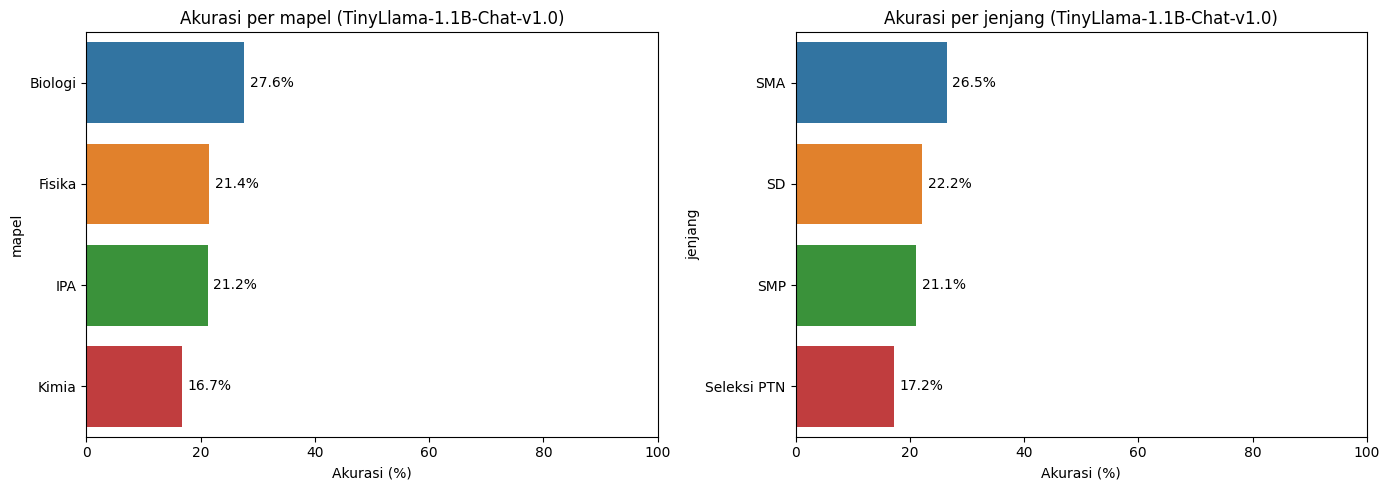

In [18]:
# 7. (Opsional) Grafik akurasi per mapel dan jenjang untuk model yang baru dijalankan
import matplotlib.pyplot as plt
import seaborn as sns_plot
import os
import pandas as pd

# Jika path_hasil tidak ada di memori, rekonstruksi otomatis dari Konfigurasi
if 'path_hasil' not in globals():
    nama_clean = NAMA_MODEL.split("/")[-1]
    path_hasil = f"{OUT_DIR}/hasil_{nama_clean}_{N_SHOT}shot{'_pilot' if PILOT else ''}.csv"

# Gunakan path_hasil, jika tidak ketemu coba cek di dalam subfolder arsip_pilot
path_grafik = path_hasil
if not os.path.exists(path_grafik):
    nama_file = os.path.basename(path_hasil)
    path_grafik = os.path.join(OUT_DIR, "arsip_pilot", nama_file)

assert os.path.exists(path_grafik), f"Berkas hasil tidak ditemukan di {path_hasil} maupun di subfolder arsip_pilot."

h = pd.read_csv(path_grafik)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a, kolom in zip(ax, ["mapel", "jenjang"]):
    d = h.groupby(kolom)["benar"].mean().mul(100).sort_values(ascending=False).reset_index()
    sns_plot.barplot(data=d, x="benar", y=kolom, hue=kolom, legend=False, ax=a)
    a.set_xlim(0, 100); a.set_xlabel("Akurasi (%)"); a.set_title(f"Akurasi per {kolom} ({NAMA_MODEL.split('/')[-1]})")
    for i, v in enumerate(d["benar"]):
        a.text(v + 1, i, f"{v:.1f}%", va="center")
plt.tight_layout(); plt.show()

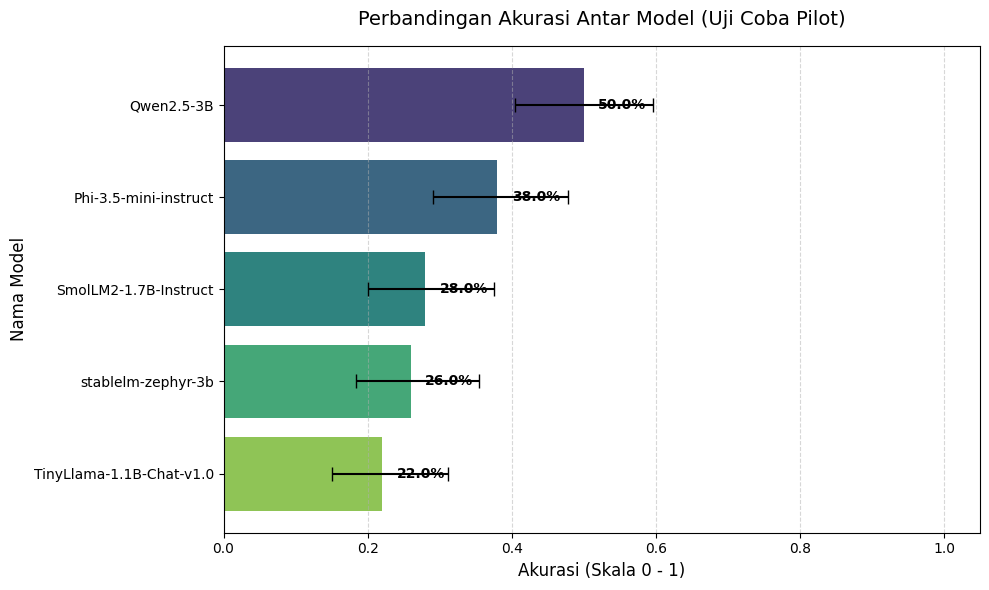

In [19]:
# 8. (Opsional) Visualisasi perbandingan akurasi antar semua model
import matplotlib.pyplot as plt
import seaborn as sns_plot

# Memastikan data rekap sudah siap
if 'rekap' in globals() and not rekap.empty:
    # Sederhanakan nama file untuk tampilan grafik yang lebih bersih
    df_plot = rekap.copy()
    df_plot['model_clean'] = df_plot['file'].apply(lambda x: x.replace('hasil_', '').replace('_0shot_pilot.csv', '').replace('_pilot.csv', ''))

    # Urutkan berdasarkan akurasi tertinggi
    df_plot = df_plot.sort_values(by='akurasi', ascending=False)

    plt.figure(figsize=(10, 6))
    # Membuat plot batang
    ax = sns_plot.barplot(data=df_plot, x='akurasi', y='model_clean', palette='viridis', hue='model_clean', legend=False)

    # Menambahkan error bar manual menggunakan Confidence Interval (CI) Wilson yang sudah dihitung
    for i, row in enumerate(df_plot.itertuples()):
        # Menghitung rentang error kiri dan kanan dari nilai akurasi
        left_err = row.akurasi - row.ci_bawah
        right_err = row.ci_atas - row.akurasi

        # Gambar error bar horizontal
        plt.errorbar(x=row.akurasi, y=i, xerr=[[left_err], [right_err]], fmt='none', c='black', capsize=5)

        # Tambahkan teks label nilai akurasi di ujung kanan bar
        plt.text(row.akurasi + 0.02, i, f"{row.akurasi*100:.1f}%", va='center', fontweight='bold')

    plt.title("Perbandingan Akurasi Antar Model (Uji Coba Pilot)", fontsize=14, pad=15)
    plt.xlabel("Akurasi (Skala 0 - 1)", fontsize=12)
    plt.ylabel("Nama Model", fontsize=12)
    plt.xlim(0, 1.05)
    plt.grid(axis='x', linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()
else:
    print("Data rekap belum dimuat. Silakan jalankan kembali Sel 5 terlebih dahulu.")